# Next-day fire spread training setup

This notebook prepares [Next Day Wildfire Spread](https://www.kaggle.com/datasets/fantineh/next-day-wildfire-spread) for U-Net training: the tile index, input normalization, a baseline to beat, and the PyTorch data loader. Training is not started here yet.

Each tile is 64 by 64 km at 1 km per pixel, somewhere in the contiguous US between 2012 and 2020. The inputs are 11 weather, fuel, terrain, and population grids plus today's fire. The label is tomorrow's fire. Source: [Huot et al. 2022](https://arxiv.org/abs/2112.02447).

It runs in two places:

- **Kaggle.** All 19 files, about 4 GB, are mounted under `/kaggle/input/`. Use this for training.
- **Locally.** It reads one file per split from `data/ndws/`, downloading through the Kaggle API what is missing, about 570 MB in total.

## Settings

In [1]:
import contextlib
import io
import shutil
import struct
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

DATASET = "fantineh/next-day-wildfire-spread"
TILE_SIZE = 64

# Input channel order.
INPUT_FEATURES = (
    "elevation",  # meters
    "th",  # wind direction, degrees clockwise from north
    "vs",  # wind speed, meters per second
    "tmmn",  # minimum temperature, kelvin
    "tmmx",  # maximum temperature, kelvin
    "sph",  # specific humidity
    "pr",  # precipitation, millimeters
    "pdsi",  # Palmer Drought Severity Index
    "NDVI",  # vegetation index, stored scaled rather than -1 to 1
    "population",  # population density
    "erc",  # energy release component, BTU per square foot
    "PrevFireMask",  # today's fire: 1 fire, 0 no fire, -1 uncertain
)
LABEL = "FireMask"  # tomorrow's fire, same values as PrevFireMask

# Our split name and the authors' file prefix. Their eval files are our val split.
SPLITS = {"train": "train", "val": "eval", "test": "test"}
LOCAL_SHARDS = (
    "next_day_wildfire_spread_train_00.tfrecord",
    "next_day_wildfire_spread_eval_00.tfrecord",
    "next_day_wildfire_spread_test_01.tfrecord",
)
CLIP_PERCENTILES = (0.1, 99.9)
# The source data has fill values, not weather: wind directions near -500000 and
# temperatures of 0 K. Pixels outside these ranges are treated as missing.
VALID_RANGES = {"th": (0, 360), "tmmn": (200, 330), "tmmx": (200, 330)}
SEED = 42

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    OUTPUT_DIR = Path("/kaggle/working")
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    LOCAL_DATA = REPO / "data" / "ndws"
    OUTPUT_DIR = REPO / "data" / "training"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Running on", "Kaggle" if ON_KAGGLE else "this machine")

Running on this machine


## Kaggle access

On Kaggle, add the dataset to the notebook with **Add Input**. Locally, the Kaggle API reads `~/.kaggle/kaggle.json`.

In [2]:
def find_kaggle_root(slug):
    """Find a mounted dataset. Kaggle has used more than one mount layout."""
    for pattern in (slug, f"*/{slug}", f"*/*/{slug}"):
        matches = sorted(Path("/kaggle/input").glob(pattern))
        if matches:
            return matches[0]
    raise FileNotFoundError(f"Add {slug} to this notebook with Add Input")


def download_local_shards():
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    LOCAL_DATA.mkdir(parents=True, exist_ok=True)
    for name in LOCAL_SHARDS:
        target = LOCAL_DATA / name
        if target.exists():
            continue
        # Kaggle sends some files as {name}.zip.
        zipped = target.with_name(target.name + ".zip")
        if not zipped.exists():
            print(f"Downloading {name}")
            with contextlib.redirect_stdout(io.StringIO()):
                api.dataset_download_file(DATASET, name, path=LOCAL_DATA, quiet=True)
        if zipped.exists():
            with zipfile.ZipFile(zipped) as archive, archive.open(archive.namelist()[0]) as source:
                with target.open("wb") as destination:
                    shutil.copyfileobj(source, destination)
            zipped.unlink()


if ON_KAGGLE:
    DATA_ROOT = find_kaggle_root(DATASET.split("/")[1])
else:
    download_local_shards()
    DATA_ROOT = LOCAL_DATA
print("Data:", DATA_ROOT)

Data: /Users/lokeshp/Projects/AIS_SkyAlert/skyalert/data/ndws


## Reading the files

The files are TFRecords of TensorFlow Examples. This reader parses them with NumPy so TensorFlow is not needed. It is the same parsing as `inspect_ndws.py`, kept in the notebook so it runs on Kaggle.

In [3]:
def read_varint(data, index):
    result = 0
    shift = 0
    while True:
        byte = data[index]
        index += 1
        result |= (byte & 0x7F) << shift
        if byte < 128:
            return result, index
        shift += 7


def parse_fields(data):
    fields = []
    index = 0
    while index < len(data):
        key, index = read_varint(data, index)
        number, wire_type = key >> 3, key & 7
        if wire_type == 0:
            value, index = read_varint(data, index)
        elif wire_type == 2:
            length, index = read_varint(data, index)
            value = data[index : index + length]
            index += length
        elif wire_type == 5:
            value = data[index : index + 4]
            index += 4
        else:
            raise ValueError(f"Unsupported protobuf wire type {wire_type}")
        fields.append((number, value))
    return fields


def field(data, number):
    return next(value for field_number, value in parse_fields(data) if field_number == number)


def parse_example(blob):
    """Return one example as a dict of feature name to a 64 by 64 float32 grid."""
    grids = {}
    for number, entry in parse_fields(field(blob, 1)):
        if number != 1:
            continue
        key = field(entry, 1).decode()
        packed = field(field(field(entry, 2), 2), 1)
        grids[key] = np.frombuffer(packed, dtype="<f4").reshape(TILE_SIZE, TILE_SIZE)
    return grids


def read_records(path):
    """Yield each example. A record is its length, a length checksum, the data, and a data checksum."""
    with path.open("rb") as records:
        while header := records.read(12):
            (length,) = struct.unpack("<Q", header[:8])
            blob = records.read(length)
            records.read(4)
            yield parse_example(blob)


def load_split(split):
    paths = sorted(DATA_ROOT.glob(f"next_day_wildfire_spread_{SPLITS[split]}_*.tfrecord"))
    if not paths:
        raise FileNotFoundError(f"No {SPLITS[split]} files in {DATA_ROOT}")
    inputs, labels, rows = [], [], []
    for path in paths:
        for position, grids in enumerate(read_records(path)):
            inputs.append(np.stack([grids[name] for name in INPUT_FEATURES]))
            labels.append(grids[LABEL].astype(np.int8))
            rows.append({"split": split, "file": path.name, "position": position})
    return np.stack(inputs), np.stack(labels), rows


data, rows = {}, []
for split in SPLITS:
    inputs, labels, split_rows = load_split(split)
    data[split] = (inputs, labels)
    rows += split_rows
    files = len({row["file"] for row in split_rows})
    print(f"{split}: {len(labels)} tiles from {files} files, inputs {inputs.shape}, labels {labels.shape}")

train: 1000 tiles from 1 files, inputs (1000, 12, 64, 64), labels (1000, 64, 64)


val: 1000 tiles from 1 files, inputs (1000, 12, 64, 64), labels (1000, 64, 64)


test: 689 tiles from 1 files, inputs (689, 12, 64, 64), labels (689, 64, 64)


## Tile index

One row per tile, saved as `spread_index.csv`. Uncertain label pixels (-1) are cloud or missing data. They are left out of the loss and the scores, so the fire share is out of the pixels that count.

In [4]:
PREV = INPUT_FEATURES.index("PrevFireMask")


def missing_inputs(inputs):
    """True where any input with a valid range is outside it."""
    missing = np.zeros((inputs.shape[0], TILE_SIZE, TILE_SIZE), dtype=bool)
    for name, (low, high) in VALID_RANGES.items():
        plane = inputs[:, INPUT_FEATURES.index(name)]
        missing |= (plane < low) | (plane > high)
    return missing


counts = []
for split in SPLITS:
    inputs, labels = data[split]
    counts.append(
        pd.DataFrame(
            {
                "prev_fire_pixels": (inputs[:, PREV] == 1).sum(axis=(1, 2)),
                "fire_pixels": (labels == 1).sum(axis=(1, 2)),
                "uncertain_pixels": (labels == -1).sum(axis=(1, 2)),
                "missing_input_pixels": missing_inputs(inputs).sum(axis=(1, 2)),
            }
        )
    )
index = pd.concat([pd.DataFrame(rows), pd.concat(counts, ignore_index=True)], axis=1)
index.to_csv(OUTPUT_DIR / "spread_index.csv", index=False)

summary = (
    index.assign(valid_pixels=TILE_SIZE**2 - index.uncertain_pixels)
    .groupby("split", sort=False)
    .agg(
        tiles=("position", "size"),
        tiles_without_fire_tomorrow=("fire_pixels", lambda pixels: int((pixels == 0).sum())),
        tiles_with_missing_inputs=("missing_input_pixels", lambda pixels: int((pixels > 0).sum())),
        fire_pixels=("fire_pixels", "sum"),
        valid_pixels=("valid_pixels", "sum"),
    )
)
summary["fire_share"] = (summary.fire_pixels / summary.valid_pixels).round(4)
summary

,tiles,tiles_without_fire_tomorrow,tiles_with_missing_inputs,fire_pixels,valid_pixels,fire_share
split,,,,,,
train,1000,146,36,51271,3982436,0.0129
val,1000,110,26,45096,3978515,0.0113
test,689,78,27,27668,2747518,0.0101


## Baseline to beat

Persistence predicts that tomorrow's fire is exactly today's fire. A spread model is only useful if it beats this. The paper reports 35.7% precision and 27.3% recall for persistence on its test set. Our numbers come from the full 64 by 64 tile and can differ from theirs.

In [5]:
def persistence_scores(split):
    inputs, labels = data[split]
    predicted = inputs[:, PREV] == 1
    actual = labels == 1
    valid = labels != -1
    hits = (predicted & actual & valid).sum()
    return {
        "precision": hits / (predicted & valid).sum(),
        "recall": hits / (actual & valid).sum(),
        "iou": hits / ((predicted | actual) & valid).sum(),
    }


baseline = pd.DataFrame({split: persistence_scores(split) for split in ("val", "test")}).T.round(3)
baseline.to_csv(OUTPUT_DIR / "spread_baseline.csv")
baseline

,precision,recall,iou
val,0.232,0.157,0.103
test,0.311,0.230,0.153


## Normalization

The inputs are on very different scales, from specific humidity near 0.007 to NDVI in the thousands.

1. Pixels outside `VALID_RANGES` are fill values, so they are marked missing and left out of the stats.
2. Each feature is clipped to its 0.1 and 99.9 percentiles on the train split, then standardized with the train mean and standard deviation.
3. Missing pixels are set to 0, the train mean after standardizing.

Today's fire passes through unchanged. The stats are saved as `spread_feature_stats.csv`, because new data must be scaled the same way at prediction time.

In [6]:
def mark_missing(inputs):
    for name, (low, high) in VALID_RANGES.items():
        plane = inputs[:, INPUT_FEATURES.index(name)]
        plane[(plane < low) | (plane > high)] = np.nan


def feature_stats(train_inputs):
    rows = []
    for channel, name in enumerate(INPUT_FEATURES):
        if name == "PrevFireMask":
            rows.append({"feature": name, "low": -1.0, "high": 1.0, "mean": 0.0, "std": 1.0})
            continue
        values = train_inputs[:, channel]
        low, high = np.nanpercentile(values, CLIP_PERCENTILES)
        clipped = np.clip(values, low, high)
        rows.append(
            {
                "feature": name,
                "low": low,
                "high": high,
                "mean": np.nanmean(clipped),
                "std": max(np.nanstd(clipped), 1e-6),
            }
        )
    return pd.DataFrame(rows).set_index("feature")


def normalize(inputs, stats):
    """Clip, standardize, and fill missing pixels in place, so the train split is not held twice."""
    for channel, name in enumerate(INPUT_FEATURES):
        low, high, mean, std = stats.loc[name, ["low", "high", "mean", "std"]]
        plane = inputs[:, channel]
        np.clip(plane, low, high, out=plane)
        plane -= mean
        plane /= std
        plane[np.isnan(plane)] = 0.0


for split in SPLITS:
    mark_missing(data[split][0])
stats = feature_stats(data["train"][0])
stats.to_csv(OUTPUT_DIR / "spread_feature_stats.csv")
for split in SPLITS:
    normalize(data[split][0], stats)

train_inputs = data["train"][0]
check = pd.DataFrame(
    {
        "train_mean": train_inputs.mean(axis=(0, 2, 3)),
        "train_std": train_inputs.std(axis=(0, 2, 3)),
        "min": train_inputs.min(axis=(0, 2, 3)),
        "max": train_inputs.max(axis=(0, 2, 3)),
    },
    index=INPUT_FEATURES,
).round(3)
stats.round(4).join(check)

,low,high,mean,std,train_mean,train_std,min,max
feature,,,,,,,,
elevation,0.0000,3712.0000,1062.2140,887.3037,-0.000,1.000,-1.197,2.986000
th,0.0000,337.7846,198.1370,70.8875,-0.000,0.998,-2.795,1.970000
vs,0.0000,8.3910,3.5856,1.2770,-0.000,1.000,-2.808,3.763000
tmmn,257.8917,297.8863,283.4177,6.9532,-0.000,0.999,-3.671,2.081000
tmmx,268.7154,314.2548,299.1474,6.9723,-0.000,0.999,-4.365,2.167000
sph,0.0000,0.0193,0.0064,0.0037,-0.000,1.000,-1.720,3.448000
pr,-0.1806,19.1274,0.2533,1.3335,-0.000,1.000,-0.325,14.154000
pdsi,-5.7484,6.1044,-1.1393,2.3811,-0.000,1.000,-1.936,3.042000
NDVI,-3715.0000,9237.0000,5359.5681,2184.8667,0.000,1.000,-4.153,1.775000


## PyTorch data loader

Each item is the inputs as `(12, 64, 64)` float32, the target as `(1, 64, 64)` float32 of 0 and 1, and a `(1, 64, 64)` boolean mask of the pixels that count. The loss and the scores should only use pixels where the mask is true.

In [7]:
import torch
from torch.utils.data import DataLoader, Dataset


class SpreadTiles(Dataset):
    def __init__(self, inputs, labels):
        self.inputs = torch.from_numpy(inputs)
        self.labels = torch.from_numpy(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, position):
        label = self.labels[position][None]
        return self.inputs[position], (label == 1).float(), label != -1


splits = {split: SpreadTiles(*data[split]) for split in SPLITS}
for split, dataset in splits.items():
    print(f"{split}: {len(dataset)} tiles")

train: 1000 tiles
val: 1000 tiles
test: 689 tiles


In [8]:
loader = DataLoader(splits["train"], batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(SEED))
inputs, targets, valid = next(iter(loader))
print("inputs ", tuple(inputs.shape), inputs.dtype)
print("targets", tuple(targets.shape), targets.dtype, "values", targets.unique().tolist())
print("valid  ", tuple(valid.shape), valid.dtype, f"{valid.float().mean():.3f} of pixels count")
print(f"fire share among counted pixels {targets[valid].mean():.4f}")

inputs  (16, 12, 64, 64) torch.float32
targets (16, 1, 64, 64) torch.float32 values [0.0, 1.0]
valid   (16, 1, 64, 64) torch.bool 0.975 of pixels count
fire share among counted pixels 0.0119


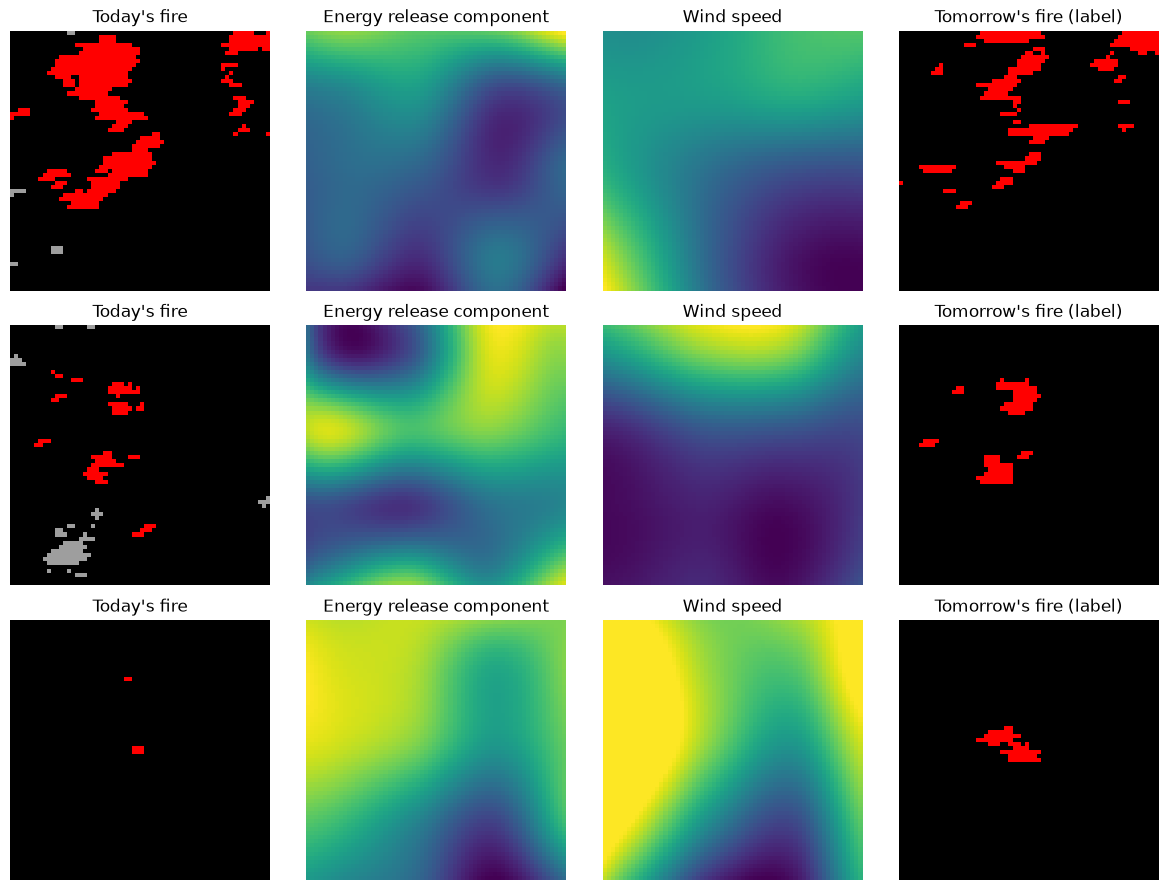

In [9]:
FIRE_COLORS = ListedColormap(["#9e9e9e", "black", "red"])  # uncertain, no fire, fire
PANELS = (("PrevFireMask", "Today's fire"), ("erc", "Energy release component"), ("vs", "Wind speed"))

busiest = targets.sum(dim=(1, 2, 3)).argsort(descending=True)[:3]
fig, axes = plt.subplots(len(busiest), len(PANELS) + 1, figsize=(12, 3 * len(busiest)), squeeze=False)
for row, sample in enumerate(busiest):
    for column, (name, title) in enumerate(PANELS):
        grid = inputs[sample, INPUT_FEATURES.index(name)]
        if name == "PrevFireMask":
            axes[row, column].imshow(grid, cmap=FIRE_COLORS, vmin=-1, vmax=1)
        else:
            axes[row, column].imshow(grid, cmap="viridis")
        axes[row, column].set_title(title)
    tomorrow = torch.where(valid[sample, 0], targets[sample, 0], torch.tensor(-1.0))
    axes[row, -1].imshow(tomorrow, cmap=FIRE_COLORS, vmin=-1, vmax=1)
    axes[row, -1].set_title("Tomorrow's fire (label)")
for axis in axes.flat:
    axis.axis("off")
plt.tight_layout()

In [10]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Training device:", device)

Training device: mps


## Model

U-Net Light from [Pereira et al. 2021](https://arxiv.org/abs/2101.03409): four levels down, 16 filters in the first layer and twice as many at each level, batch normalization, and dropout at the bottom. It outputs one logit per pixel.

In [11]:
import time

import torch.nn as nn
import torch.nn.functional as F


def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, in_channels, base=16, depth=4, dropout=0.1):
        super().__init__()
        widths = [base * 2**level for level in range(depth)]
        self.down = nn.ModuleList()
        channels = in_channels
        for width in widths:
            self.down.append(conv_block(channels, width))
            channels = width
        self.bottom = conv_block(widths[-1], widths[-1] * 2)
        self.dropout = nn.Dropout2d(dropout)
        self.up = nn.ModuleList(nn.ConvTranspose2d(width * 2, width, 2, stride=2) for width in reversed(widths))
        self.merge = nn.ModuleList(conv_block(width * 2, width) for width in reversed(widths))
        self.head = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        skips = []
        for block in self.down:
            x = block(x)
            skips.append(x)
            x = F.max_pool2d(x, 2)
        x = self.dropout(self.bottom(x))
        for up, merge, skip in zip(self.up, self.merge, reversed(skips)):
            x = merge(torch.cat([up(x), skip], dim=1))
        return self.head(x)


parameters = sum(parameter.numel() for parameter in UNet(len(INPUT_FEATURES)).parameters())
print(f"U-Net Light: {parameters:,} parameters")

U-Net Light: 1,943,873 parameters


## Training

- Random 32 by 32 crops of the train tiles, as in the paper. No flips or rotations, because they would make the wind direction channel wrong.
- Binary cross-entropy on counted pixels only. Fire is about 1% of counted pixels, so fire pixels get `POS_WEIGHT` times the weight.
- Val is scored on full 64 by 64 tiles after every epoch. The weights with the best val PR-AUC are saved as `spread_unet.pt`, and training stops after `PATIENCE` epochs without improvement.
- Locally it runs 2 epochs, only to check the code.

In [12]:
CROP = 32
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
POS_WEIGHT = 10.0
MAX_EPOCHS = 50 if ON_KAGGLE else 2
PATIENCE = 5
WEIGHTS_PATH = OUTPUT_DIR / "spread_unet.pt"


def random_crops(tensors, size):
    """Cut the same random window from each sample's inputs, target, and valid mask."""
    batch = tensors[0].shape[0]
    tops = torch.randint(0, TILE_SIZE - size + 1, (batch,)).tolist()
    lefts = torch.randint(0, TILE_SIZE - size + 1, (batch,)).tolist()
    return [
        torch.stack([tensor[i, :, top : top + size, left : left + size] for i, (top, left) in enumerate(zip(tops, lefts))])
        for tensor in tensors
    ]


def masked_loss(logits, target, valid):
    weight = torch.tensor(POS_WEIGHT, device=logits.device)
    loss = F.binary_cross_entropy_with_logits(logits, target, pos_weight=weight, reduction="none")
    return loss[valid].mean()


@torch.no_grad()
def predict(model, dataset):
    """Fire probability and label for every counted pixel, on full tiles."""
    model.eval()
    probabilities, targets = [], []
    for inputs, target, valid in DataLoader(dataset, batch_size=256):
        probability = torch.sigmoid(model(inputs.to(device))).cpu()
        probabilities.append(probability[valid])
        targets.append(target[valid])
    return torch.cat(probabilities), torch.cat(targets)


def average_precision(probabilities, targets):
    """Area under the precision-recall curve."""
    hits = targets[probabilities.argsort(descending=True)]
    precision = hits.cumsum(0) / torch.arange(1, len(hits) + 1)
    return ((precision * hits).sum() / hits.sum()).item()


torch.manual_seed(SEED)
model = UNet(len(INPUT_FEATURES)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
train_loader = DataLoader(splits["train"], batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

history, best, epochs_since_best = [], -1.0, 0
for epoch in range(1, MAX_EPOCHS + 1):
    started = time.time()
    model.train()
    losses = []
    for batch in train_loader:
        inputs, target, valid = random_crops([tensor.to(device) for tensor in batch], CROP)
        loss = masked_loss(model(inputs), target, valid)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    val_pr_auc = average_precision(*predict(model, splits["val"]))
    history.append(
        {"epoch": epoch, "train_loss": np.mean(losses), "val_pr_auc": val_pr_auc, "seconds": time.time() - started}
    )
    improved = val_pr_auc > best
    print(
        f"epoch {epoch:2d}  train loss {np.mean(losses):.4f}  val PR-AUC {val_pr_auc:.4f}"
        f"  {time.time() - started:.0f}s{'  saved' if improved else ''}"
    )
    if improved:
        best, epochs_since_best = val_pr_auc, 0
        torch.save(model.state_dict(), WEIGHTS_PATH)
    else:
        epochs_since_best += 1
        if epochs_since_best >= PATIENCE:
            print(f"No improvement for {PATIENCE} epochs, stopping")
            break

pd.DataFrame(history).to_csv(OUTPUT_DIR / "spread_history.csv", index=False)

epoch  1  train loss 0.7750  val PR-AUC 0.0248  6s  saved


epoch  2  train loss 0.6683  val PR-AUC 0.1171  1s  saved


## Test scores

The best weights are scored on the test split. The fire threshold is the one with the best F1 on val, so the test split is not used to choose it. Persistence has no PR-AUC because it only predicts yes or no.

In [13]:
def best_f1_threshold(probabilities, targets):
    order = probabilities.argsort(descending=True)
    hits = targets[order].cumsum(0)
    f1 = 2 * hits / (torch.arange(1, len(order) + 1) + targets.sum())
    return probabilities[order][f1.argmax()].item()


def scores(probabilities, targets, threshold):
    predicted = probabilities >= threshold
    actual = targets == 1
    hits = (predicted & actual).sum().item()
    return {
        "pr_auc": average_precision(probabilities, targets),
        "precision": hits / max(predicted.sum().item(), 1),
        "recall": hits / max(actual.sum().item(), 1),
        "iou": hits / max((predicted | actual).sum().item(), 1),
    }


model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device))
threshold = best_f1_threshold(*predict(model, splits["val"]))
results = pd.DataFrame(
    {
        "U-Net Light": scores(*predict(model, splits["test"]), threshold),
        "Persistence": {"pr_auc": np.nan, **baseline.loc["test"].to_dict()},
    }
).T.round(3)
results.to_csv(OUTPUT_DIR / "spread_results.csv")
print(f"Fire threshold from val: {threshold:.3f}")
results

Fire threshold from val: 0.603


,pr_auc,precision,recall,iou
U-Net Light,0.181,0.226,0.448,0.177
Persistence,NaN,0.311,0.230,0.153


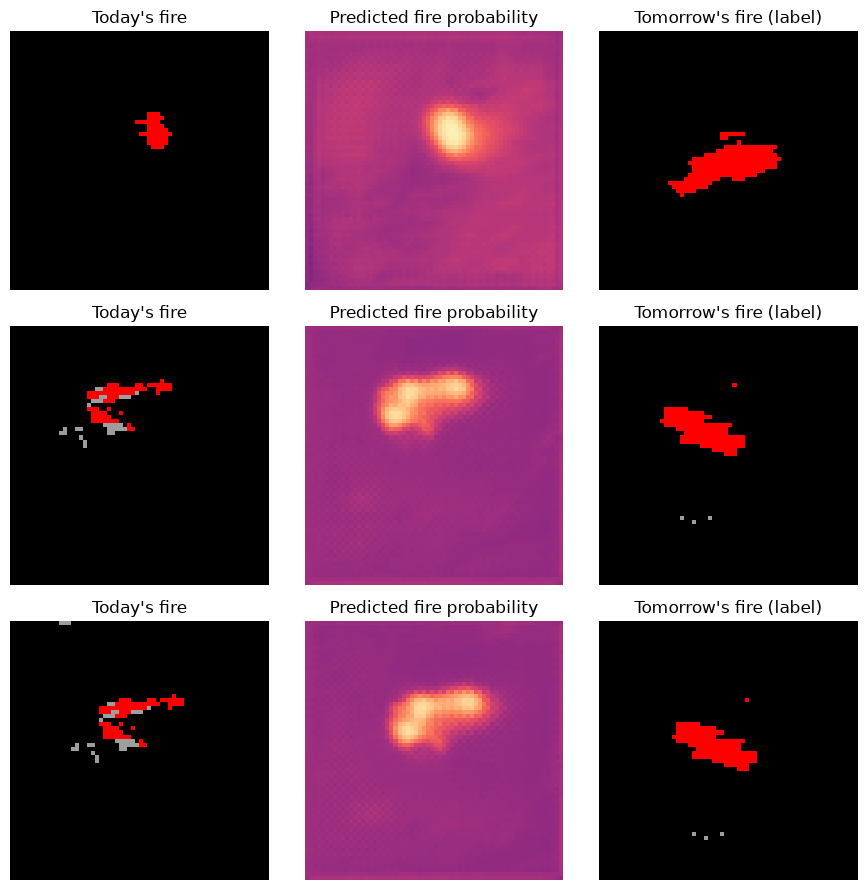

In [14]:
test_inputs, test_targets, test_valid = next(iter(DataLoader(splits["test"], batch_size=64)))
with torch.no_grad():
    test_probabilities = torch.sigmoid(model(test_inputs.to(device))).cpu()

busiest = test_targets.sum(dim=(1, 2, 3)).argsort(descending=True)[:3]
fig, axes = plt.subplots(len(busiest), 3, figsize=(9, 3 * len(busiest)), squeeze=False)
for row, sample in enumerate(busiest):
    tomorrow = torch.where(test_valid[sample, 0], test_targets[sample, 0], torch.tensor(-1.0))
    axes[row, 0].imshow(test_inputs[sample, PREV], cmap=FIRE_COLORS, vmin=-1, vmax=1)
    axes[row, 0].set_title("Today's fire")
    axes[row, 1].imshow(test_probabilities[sample, 0], cmap="magma", vmin=0, vmax=1)
    axes[row, 1].set_title("Predicted fire probability")
    axes[row, 2].imshow(tomorrow, cmap=FIRE_COLORS, vmin=-1, vmax=1)
    axes[row, 2].set_title("Tomorrow's fire (label)")
for axis in axes.flat:
    axis.axis("off")
plt.tight_layout()